# USGS streamflow download: Boise River near Twin Springs + Snake River at Moose

Downloads the full period of record of **daily mean discharge (cfs)** for two USGS gages (by gage ID), groups it by **water year**, and saves one combined CSV.

| Gage ID | Name |
|---|---|
| 13185000 | Boise River near Twin Springs, ID |
| 13013650 | Snake River at Moose, WY |

Run the cells top to bottom. In VS Code, pick a Python kernel (top right) first.

In [1]:
# Uncomment if these aren't installed in your kernel
# %pip install requests pandas matplotlib

import io
import time
import requests
import pandas as pd

## Gages and settings

In [2]:
OUT_CSV    = "usgs_flow_twin_springs_moose.csv"
OUT_ANNUAL = "usgs_flow_annual_by_water_year.csv"

# (USGS gage ID, name, state)
GAGES = [
    ("13185000", "Boise River near Twin Springs", "ID"),
    ("13013650", "Snake River at Moose",          "WY"),
]

PARAM_CD = "00060"   # discharge, cubic feet per second
STAT_CD  = "00003"   # daily mean

## Download functions

In [3]:
def http_get(url, params=None, tries=4):
    for i in range(tries):
        try:
            r = requests.get(url, params=params, timeout=300)
            r.raise_for_status()
            return r
        except Exception:
            if i == tries - 1:
                raise
            time.sleep(3 * (i + 1))


def fetch_legacy(site):
    """USGS NWIS daily-values service (tab-delimited RDB)."""
    r = http_get("https://waterservices.usgs.gov/nwis/dv/", {
        "format": "rdb", "sites": site, "parameterCd": PARAM_CD, "statCd": STAT_CD,
        "startDT": "1800-01-01", "endDT": pd.Timestamp.today().strftime("%Y-%m-%d"),
        "siteStatus": "all",
    })
    t = pd.read_csv(io.StringIO(r.text), sep="\t", comment="#", dtype=str)
    t = t.iloc[1:]                                  # drop the RDB column-format row
    val_cols = [c for c in t.columns if c.endswith(f"{PARAM_CD}_{STAT_CD}")]
    if not val_cols:
        raise ValueError("no discharge column returned")
    out = pd.DataFrame({"date": pd.to_datetime(t["datetime"])})
    out["discharge_cfs"] = pd.NA
    out["approval_code"] = pd.NA
    for c in val_cols:                              # if several series, fill gaps in order
        v = pd.to_numeric(t[c], errors="coerce")
        cd = t.get(c + "_cd")
        m = out["discharge_cfs"].isna() & v.notna().values
        out.loc[m, "discharge_cfs"] = v[m].values
        if cd is not None:
            out.loc[m, "approval_code"] = cd[m].values
    out["discharge_cfs"] = pd.to_numeric(out["discharge_cfs"], errors="coerce")
    return out


def fetch_ogc(site):
    """Newer USGS Water Data API (used if the legacy service is unavailable)."""
    url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily/items"
    params = {"monitoring_location_id": f"USGS-{site}", "parameter_code": PARAM_CD,
              "statistic_id": STAT_CD, "limit": 10000, "f": "json"}
    rows = []
    while url:
        js = http_get(url, params).json()
        for f in js.get("features", []):
            p = f.get("properties", {})
            rows.append({"date": p.get("time"), "discharge_cfs": p.get("value"),
                         "approval_code": p.get("approval_status") or p.get("qualifier")})
        nxt = [l["href"] for l in js.get("links", []) if l.get("rel") == "next"]
        url, params = (nxt[0] if nxt else None), None
    out = pd.DataFrame(rows)
    if out.empty:
        raise ValueError("no rows returned")
    out["date"] = pd.to_datetime(out["date"]).dt.tz_localize(None).dt.normalize()
    out["discharge_cfs"] = pd.to_numeric(out["discharge_cfs"], errors="coerce")
    return out


def fetch_gage(site, name, state):
    try:
        df = fetch_legacy(site)
        src = "NWIS dv"
    except Exception as e:
        print(f"  legacy service failed ({e}); trying Water Data API ...")
        df = fetch_ogc(site)
        src = "Water Data API"
    df = (df.dropna(subset=["discharge_cfs"]).drop_duplicates("date")
            .sort_values("date").reset_index(drop=True))
    df.insert(1, "gage_id", site)
    df.insert(2, "gage_name", name)
    df.insert(3, "state", state)
    print(f"  [{src}] {len(df):,} daily values, {df['date'].min().date()} -> {df['date'].max().date()}")
    return df

## Download (a minute or two)

In [4]:
frames = []
for site, name, state in GAGES:
    print(f"Fetching {site} {name} ({state}) ...")
    frames.append(fetch_gage(site, name, state))

df = pd.concat(frames, ignore_index=True)

# --- Water year: Oct 1 -> Sep 30, named for the year it ENDS (Oct 1 2019 = WY2020) ---
df["water_year"] = df["date"].dt.year + (df["date"].dt.month >= 10).astype(int)
wy_start = pd.to_datetime((df["water_year"] - 1).astype(str) + "-10-01")
df["day_of_water_year"] = (df["date"] - wy_start).dt.days + 1      # Oct 1 = 1

# --- Annual (water-year) values, repeated on every row of that gage/water year ---
df = df.sort_values(["gage_id", "water_year", "date"]).reset_index(drop=True)
g = df.groupby(["gage_id", "water_year"])
df["wy_mean_cfs"] = g["discharge_cfs"].transform("mean")
df["wy_peak_daily_cfs"] = g["discharge_cfs"].transform("max")
df["wy_min_daily_cfs"] = g["discharge_cfs"].transform("min")
peak_date = (df.sort_values("discharge_cfs", ascending=False)
               .drop_duplicates(["gage_id", "water_year"])
               .set_index(["gage_id", "water_year"])["date"])
df["wy_peak_date"] = [peak_date.get((a, b)) for a, b in zip(df["gage_id"], df["water_year"])]
# volume: cfs-day -> acre-feet (1 cfs for 1 day = 1.98347 acre-ft)
df["wy_volume_acre_ft"] = g["discharge_cfs"].transform("sum") * 1.98347
df["wy_total_flow_acre_ft"] = df["wy_volume_acre_ft"]
df["days_of_data_in_wy"] = g["date"].transform("count")            # <365 => partial/missing days

cols = ["water_year", "day_of_water_year", "date", "gage_id", "gage_name", "state",
        "discharge_cfs", "approval_code", "wy_mean_cfs", "wy_peak_daily_cfs", "wy_peak_date",
        "wy_min_daily_cfs", "wy_volume_acre_ft", "wy_total_flow_acre_ft", "days_of_data_in_wy"]
df = df[cols]
df.to_csv(OUT_CSV, index=False)

annual = (df.groupby(["gage_id", "gage_name", "water_year"])
            [["wy_mean_cfs", "wy_peak_daily_cfs", "wy_peak_date", "wy_min_daily_cfs",
              "wy_volume_acre_ft", "wy_total_flow_acre_ft", "days_of_data_in_wy"]].first().reset_index())
annual.to_csv(OUT_ANNUAL, index=False)
print(f"\nSaved {OUT_CSV}: {len(df):,} rows")
print(f"Saved {OUT_ANNUAL}: {len(annual):,} rows")

Fetching 13185000 Boise River near Twin Springs (ID) ...
  [NWIS dv] 42,221 daily values, 1911-04-01 -> 2026-11-03
Fetching 13013650 Snake River at Moose (WY) ...
  [NWIS dv] 11,470 daily values, 1995-04-06 -> 2026-11-03

Saved usgs_flow_twin_springs_moose.csv: 53,691 rows
Saved usgs_flow_annual_by_water_year.csv: 150 rows


## Look at the data

In [5]:
df.head()

,water_year,day_of_water_year,date,gage_id,gage_name,state,discharge_cfs,approval_code,wy_mean_cfs,wy_peak_daily_cfs,wy_peak_date,wy_min_daily_cfs,wy_volume_acre_ft,days_of_data_in_wy
0,1995,188,1995-04-06,13013650,Snake River at Moose,WY,980,A,5570.884956,12000,1995-06-06,980,1.248614e+06,113
1,1995,249,1995-06-06,13013650,Snake River at Moose,WY,12000,A,5570.884956,12000,1995-06-06,980,1.248614e+06,113
2,1995,250,1995-06-07,13013650,Snake River at Moose,WY,9940,A,5570.884956,12000,1995-06-06,980,1.248614e+06,113
3,1995,256,1995-06-13,13013650,Snake River at Moose,WY,9660,A,5570.884956,12000,1995-06-06,980,1.248614e+06,113
4,1995,257,1995-06-14,13013650,Snake River at Moose,WY,10200,A,5570.884956,12000,1995-06-06,980,1.248614e+06,113


In [6]:
# One row per gage per water year
annual

,gage_id,gage_name,water_year,wy_mean_cfs,wy_peak_daily_cfs,wy_peak_date,wy_min_daily_cfs,wy_volume_acre_ft,days_of_data_in_wy
0,13013650,Snake River at Moose,1995,5570.884956,12000,1995-06-06,980,1.248614e+06,113
1,13013650,Snake River at Moose,1996,4110.838798,20900,1996-06-16,967,2.984264e+06,366
2,13013650,Snake River at Moose,1997,4874.493151,24500,1997-06-11,1090,3.528970e+06,365
3,13013650,Snake River at Moose,1998,3615.972603,11700,1998-06-04,1110,2.617843e+06,365
4,13013650,Snake River at Moose,1999,3639.479452,15800,1999-06-22,822,2.634861e+06,365
...,...,...,...,...,...,...,...,...,...
145,13185000,Boise River near Twin Springs,2023,1293.515068,9210,2023-05-02,228,9.364616e+05,365
146,13185000,Boise River near Twin Springs,2024,984.188525,5170,2024-06-04,254,7.144717e+05,366
147,13185000,Boise River near Twin Springs,2025,1097.106849,5950,2025-05-11,246,7.942687e+05,365
148,13185000,Boise River near Twin Springs,2026,1003.457534,4170,2026-05-13,271,7.264697e+05,365


In [7]:
# Example: one gage + water year
df[(df["gage_id"] == "13185000") & (df["water_year"] == 2017)].head()

,water_year,day_of_water_year,date,gage_id,gage_name,state,discharge_cfs,approval_code,wy_mean_cfs,wy_peak_daily_cfs,wy_peak_date,wy_min_daily_cfs,wy_volume_acre_ft,days_of_data_in_wy
50005,2017,1,2016-10-01,13185000,Boise River near Twin Springs,ID,329,A,2207.860274,11800,2017-05-07,298,1.598417e+06,365
50006,2017,2,2016-10-02,13185000,Boise River near Twin Springs,ID,331,A,2207.860274,11800,2017-05-07,298,1.598417e+06,365
50007,2017,3,2016-10-03,13185000,Boise River near Twin Springs,ID,342,A,2207.860274,11800,2017-05-07,298,1.598417e+06,365
50008,2017,4,2016-10-04,13185000,Boise River near Twin Springs,ID,351,A,2207.860274,11800,2017-05-07,298,1.598417e+06,365
50009,2017,5,2016-10-05,13185000,Boise River near Twin Springs,ID,352,A,2207.860274,11800,2017-05-07,298,1.598417e+06,365


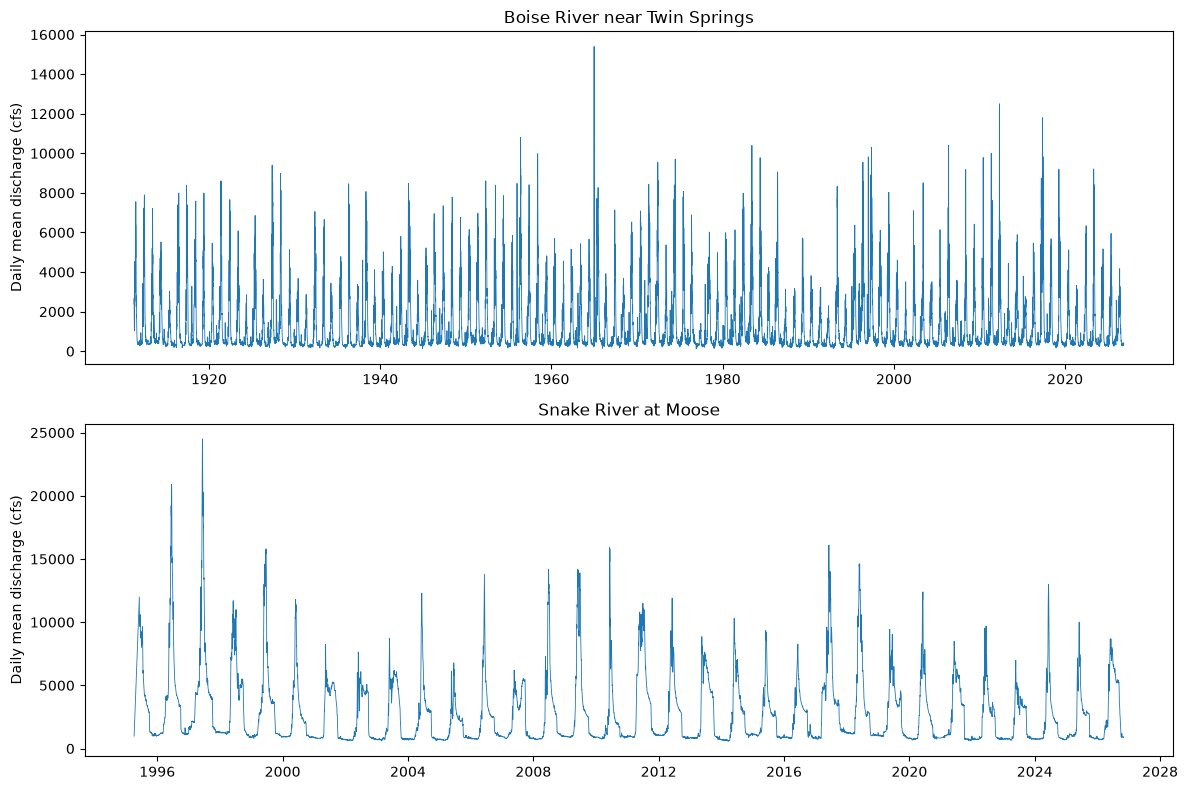

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, (gid, g) in zip(axes, df.groupby("gage_name")):
    ax.plot(g["date"], g["discharge_cfs"], lw=0.6)
    ax.set_title(gid); ax.set_ylabel("Daily mean discharge (cfs)")
plt.tight_layout(); plt.show()

In [ ]:
# Optional: also write one CSV per water year
# import os; os.makedirs("flow_by_water_year", exist_ok=True)
# for wy, g in df.groupby("water_year"):
#     g.to_csv(f"flow_by_water_year/WY{wy}.csv", index=False)